# Comparatif QLBM D1Q3 : diffusion pure vs advection-diffusion

**Objectif.** Comparer, à paramètres identiques, les deux circuits quantiques développés :

| | Diffusion (`LBM_D1Q3_Circuit_tot.ipynb`) | Advection-diffusion (`LBM_D1Q3_Advection.ipynb`) |
|---|---|---|
| équilibre | $f^{eq}_a=\omega_a\rho$ | $f^{eq}_a=\omega_a\rho\,(1+c_a u/c_s^2)$, $u=j/\rho$ |
| matrice d'équilibre locale | $E_{\rm diff}=\omega\,\mathbf 1^T$ | $E_{\rm adv}=\omega\,\mathbf 1^T+(\omega\circ c)\,c^T/c_s^2$ |
| quantités conservées | $\rho$ | $\rho$ et $j$ |
| condition initiale | gaussienne, $j=0$ | fond $\bar\rho=1$ + gaussienne, $j=c_s\,\delta\rho$ (onde progressive) |
| équation macroscopique | $\partial_t\rho=D\,\partial_{xx}\rho$, $D=c_s^2(\tau-\tfrac12)$ | $\partial_t\delta\rho+c_s\partial_x\delta\rho=\Gamma\,\partial_{xx}\delta\rho$, $\Gamma=\tfrac12(1-c_s^2)(\tau-\tfrac12)$ |

**Paramètres communs** : $N=8$ nœuds, $\tau=0{,}8$, $T=3$ pas, $\sigma_0=1{,}5$, collision $C_{loc}$ block-encodée par FABLE (3 ancillas neuves par pas), même circuit de streaming, mêmes graines de simulation.

**Ce qu'on compare :**
1. coût du circuit : largeur, profondeur, profondeur 2-qubits, CNOT, portes, par bloc ;
2. coût du chargement : préparation d'état $|F^0\rangle$ (portes) et temps de calcul (construction, transpilation, simulation) ;
3. probabilité de succès de la post-sélection ;
4. précision pour un même nombre de *shots* (plusieurs graines) ;
5. précision du schéma classique face à la solution analytique.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from fable import fable
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import StatePreparation
from qiskit_aer import AerSimulator

np.set_printoptions(precision=4, suppress=True)

# parametres communs
tau, k, T = 0.8, 3, 3
N = 2**k; D = 4*N
sigma0, x0 = 1.5, N/2
x = np.arange(N)
w   = np.array([2/3, 1/6, 1/6])          # ordre (0, -, +)
c   = np.array([0, -1, +1])
cs2 = (w*c**2).sum(); cs = np.sqrt(cs2)
print(f"N = {N}, tau = {tau}, T = {T} pas, c_s = {cs:.4f}")

N = 8, tau = 0.8, T = 3 pas, c_s = 0.5774


## 1. Les deux modèles

Chaque modèle est décrit par sa matrice d'équilibre locale $E$ (donc $C_{loc}=(1-\tfrac1\tau)I_3+E/\tau$), sa condition initiale $F^0$, son « fond » $\bar\rho$ et sa solution analytique.

La **précision** est toujours mesurée sur le **signal physique** $\rho-\bar\rho$ : $\rho$ en diffusion ($\bar\rho=0$), la perturbation $\delta\rho$ en advection. Le fond constant ne porte aucune physique.

In [2]:
def lbm_step(f, E):
    # collision BGK f <- f - (f - E f)/tau puis streaming ; f de forme (3, N)
    fs = f - (f - E @ f)/tau
    return np.stack([fs[0], np.roll(fs[1], -1), np.roll(fs[2], +1)])

def periodique(xx, centre, s2):
    return sum(np.exp(-(xx - centre - m*N)**2/(2*s2)) for m in range(-3, 4))

g0 = np.exp(-(x - x0)**2/(2*sigma0**2))          # gaussienne commune

# --- diffusion pure
E_diff = np.outer(w, np.ones(3))
D_diff = cs2*(tau - 0.5)
diff = dict(nom="diffusion", E=E_diff, fond=0.0,
            f0=w[:, None]*g0,
            ana=lambda t, xx=x: sigma0/np.sqrt(sigma0**2 + 2*D_diff*t)*periodique(xx, x0, sigma0**2 + 2*D_diff*t))

# --- advection-diffusion (onde progressive)
E_adv = E_diff + np.outer(w*c, c)/cs2
Gam = 0.5*(1 - cs2)*(tau - 0.5)
rho_bar = 1.0
adv = dict(nom="advection-diffusion", E=E_adv, fond=rho_bar,
           f0=w[:, None]*(rho_bar + g0) + (w*c/cs2)[:, None]*(cs*g0),   # f^eq(rho0, j0 = cs * drho0)
           ana=lambda t, xx=x: rho_bar + sigma0/np.sqrt(sigma0**2 + 2*Gam*t)*periodique(xx, x0 + cs*t, sigma0**2 + 2*Gam*t))

modeles = [diff, adv]
for m in modeles:
    m["C_loc"] = (1 - 1/tau)*np.eye(3) + m["E"]/tau
    m["F0"] = np.concatenate([m["f0"].reshape(-1), np.zeros(N)])        # R^{4N}
    m["masse"] = m["F0"].sum()
    f = m["f0"].copy(); fmin = f.min()
    for _ in range(T):
        f = lbm_step(f, m["E"]); fmin = min(fmin, f.min())
    m["rho_lbm"] = f.sum(axis=0)
    m["signal"] = m["rho_lbm"] - m["fond"]
    print(f"--- {m['nom']}")
    print("C_loc =\n", m["C_loc"])
    print(f"  colonnes de somme 1 : {np.allclose(m['C_loc'].sum(axis=0), 1)} | min des f sur {T} pas : {fmin:.4f} | masse : {m['masse']:.4f}")
    print(f"  masse du signal / masse totale : {(m['f0'].sum() - N*m['fond'])/m['f0'].sum():.2f}")
print(f"\nD (diffusion) = {D_diff:.4f}   Gamma (advection) = {Gam:.4f}")

--- diffusion
C_loc =
 [[ 0.5833  0.8333  0.8333]
 [ 0.2083 -0.0417  0.2083]
 [ 0.2083  0.2083 -0.0417]]
  colonnes de somme 1 : True | min des f sur 3 pas : 0.0048 | masse : 3.7229
  masse du signal / masse totale : 1.00
--- advection-diffusion
C_loc =
 [[ 0.5833  0.8333  0.8333]
 [ 0.2083  0.5833 -0.4167]
 [ 0.2083 -0.4167  0.5833]]
  colonnes de somme 1 : True | min des f sur 3 pas : 0.0447 | masse : 11.7229
  masse du signal / masse totale : 0.32

D (diffusion) = 0.1000   Gamma (advection) = 0.1000


## 2. Construction des deux circuits

Même structure pour les deux : préparation de $|F^0\rangle$ → $T\times$[collision FABLE sur `dir` + ancillas du pas, puis streaming $S$ sur `pos` + `dir`] → mesures.
Seule la matrice $C_{loc}$ passée à FABLE (et l'état préparé) diffère.

On vérifie d'abord, en calcul exact (statevector), que chaque circuit reproduit son LBM classique.

In [3]:
def increment(m):
    # |i> -> |i+1 mod 2^m>  (= P+)
    qc = QuantumCircuit(m, name="+1")
    for j in reversed(range(m)):
        if j == 0: qc.x(0)
        else: qc.mcx(list(range(j)), j)
    return qc

inc = increment(k)
circ_S = QuantumCircuit(k + 2, name="S")
circ_S.append(inc.inverse().to_gate(label="P-").control(2, ctrl_state='01'), [k, k+1] + list(range(k)))
circ_S.append(inc.to_gate(label="P+").control(2, ctrl_state='10'), [k, k+1] + list(range(k)))

def construire(m):
    t0 = time.perf_counter()
    C4 = np.zeros((4, 4)); C4[:3, :3] = m["C_loc"]
    circ_loc, alpha = fable(C4, 1e-6)
    t1 = time.perf_counter()
    n_anc = circ_loc.num_qubits - 2
    pos = QuantumRegister(k, "pos"); dr = QuantumRegister(2, "dir")
    anc = [QuantumRegister(n_anc, f"anc{t}") for t in range(T)]
    c_anc = ClassicalRegister(n_anc*T, "c_anc"); c_out = ClassicalRegister(k + 2, "c_out")
    qc = QuantumCircuit(pos, dr, *anc, c_anc, c_out)
    prep = StatePreparation(m["F0"]/np.linalg.norm(m["F0"]), label="prep F0")
    qc.append(prep, list(pos) + list(dr))
    for t in range(T):
        qc.append(circ_loc.to_gate(label="U_C"), list(dr) + list(anc[t]))
        qc.append(circ_S.to_gate(label="S"), list(pos) + list(dr))
    qc.barrier()
    qc.measure([q for r in anc for q in r], c_anc)
    qc.measure(list(pos) + list(dr), c_out)
    t2 = time.perf_counter()
    m.update(circ=qc, circ_loc=circ_loc, alpha=alpha, prep=prep, n_anc=n_anc,
             t_fable=t1 - t0, t_circuit=t2 - t1)

def etat_final_exact(m):
    # statevector du circuit sans mesures -> proba de succes et rho post-selectionnee (exactes)
    sv = Statevector.from_instruction(m["circ"].remove_final_measurements(inplace=False)).data
    n_sys = k + 2
    ok = np.array([sv[j] for j in range(D)])          # ancillas toutes a 0 = indices < D
    p = np.sum(np.abs(ok)**2)
    F = np.abs(ok)/np.sqrt(p)
    F = F*m["masse"]/F[:3*N].sum()
    return p, F[:N] + F[N:2*N] + F[2*N:3*N]

for m in modeles:
    construire(m)
    m["p_exact"], rho_q = etat_final_exact(m)
    m["rho_q_exact"] = rho_q
    print(f"{m['nom']:22s} alpha = {m['alpha']:.4f} | |rho_circuit_exact - rho_LBM|_max = {np.abs(rho_q - m['rho_lbm']).max():.1e}"
          f" | proba de succes sur {T} pas = {m['p_exact']:.3e}")

diffusion              alpha = 1.0000 | |rho_circuit_exact - rho_LBM|_max = 3.2e-15 | proba de succes sur 3 pas = 2.197e-04


advection-diffusion    alpha = 1.0000 | |rho_circuit_exact - rho_LBM|_max = 7.3e-15 | proba de succes sur 3 pas = 2.410e-04


## 3. Coût du circuit : *width*, *depth*, portes

Comptage sur le circuit **transpilé** en portes de base `cx` (CNOT) et `u`, `optimization_level=1`, comme dans les notebooks de chaque méthode. On sépare ensuite le coût de chaque bloc.

In [4]:
def couts(qc):
    t = transpile(qc, basis_gates=["cx", "u", "measure", "reset"], optimization_level=1, seed_transpiler=0)
    ops = t.count_ops()
    return dict(qubits=t.num_qubits,
                depth=t.depth(lambda i: i.operation.name != "barrier"),
                depth_2q=t.depth(lambda i: i.operation.num_qubits == 2),
                cx=ops.get("cx", 0), u=ops.get("u", 0),
                gates=sum(v for kk, v in ops.items() if kk not in ("measure", "barrier")))

def bloc(gate, nq):
    q = QuantumCircuit(nq); q.append(gate, range(nq)); return q

for m in modeles:
    m["cout_total"] = couts(m["circ"])
    m["cout_prep"] = couts(bloc(m["prep"], k + 2))
    m["cout_coll"] = couts(m["circ_loc"])
    m["cout_strm"] = couts(circ_S)

cles = [("qubits", "width (qubits)"), ("depth", "depth"), ("depth_2q", "2-qubit depth"),
        ("cx", "CNOT"), ("u", "rotations u"), ("gates", "portes (total)")]
print(f"{'CIRCUIT COMPLET':28s}{'diffusion':>14s}{'advection':>14s}{'ecart':>10s}")
for cle, nom in cles:
    a, b = diff["cout_total"][cle], adv["cout_total"][cle]
    print(f"{nom:28s}{a:>14d}{b:>14d}{b - a:>+10d}")
print()
print(f"{'PAR BLOC (CNOT / portes / depth)':34s}{'diffusion':>20s}{'advection':>20s}{'x fois':>8s}")
for cle, nom, nb in [("cout_prep", "preparation de F0", 1), ("cout_coll", "collision U_C (FABLE)", T), ("cout_strm", "streaming S", T)]:
    a, b = diff[cle], adv[cle]
    print(f"{nom:34s}{a['cx']:>6d} /{a['gates']:>5d} /{a['depth']:>5d}{b['cx']:>8d} /{b['gates']:>5d} /{b['depth']:>5d}{nb:>8d}")

CIRCUIT COMPLET                  diffusion     advection     ecart
width (qubits)                          14            14        +0
depth                                 1641          1641        +0
2-qubit depth                          894           894        +0
CNOT                                   948           948        +0
rotations u                           1055          1055        +0
portes (total)                        2003          2003        +0

PAR BLOC (CNOT / portes / depth)             diffusion           advection  x fois
preparation de F0                     26 /   57 /   53      26 /   57 /   53       1
collision U_C (FABLE)                 22 /   42 /   36      22 /   42 /   36       3
streaming S                          314 /  659 /  583     314 /  659 /  583       3


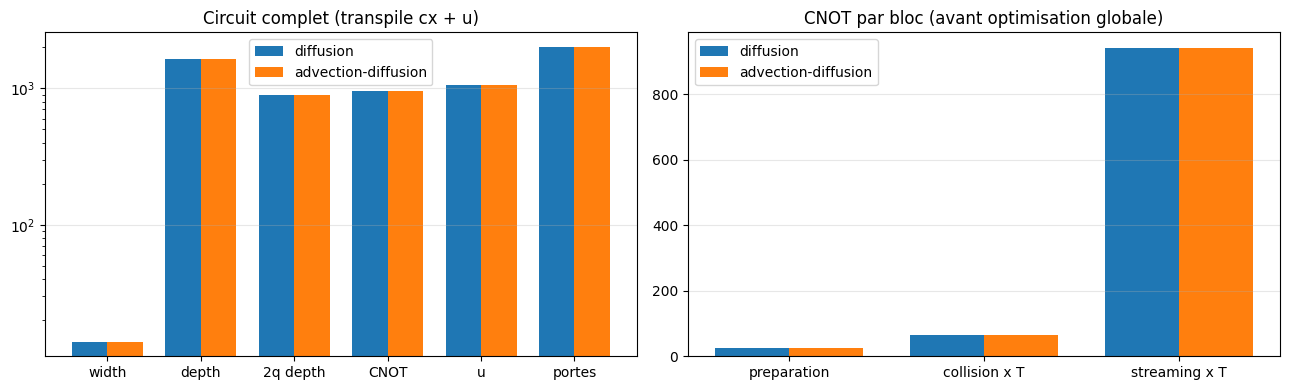

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
etiq = ["width", "depth", "2q depth", "CNOT", "u", "portes"]
xx = np.arange(len(etiq))
for i, m in enumerate(modeles):
    v = [m["cout_total"][kk] for kk, _ in cles]
    ax[0].bar(xx + (i - 0.5)*0.38, v, 0.38, label=m["nom"])
ax[0].set_xticks(xx); ax[0].set_xticklabels(etiq); ax[0].set_yscale("log"); ax[0].legend(); ax[0].grid(alpha=0.3, axis="y")
ax[0].set_title("Circuit complet (transpile cx + u)")

blocs = [("cout_prep", "preparation", 1), ("cout_coll", "collision x T", T), ("cout_strm", "streaming x T", T)]
for i, m in enumerate(modeles):
    v = [m[b]["cx"]*nb for b, _, nb in blocs]
    ax[1].bar(np.arange(3) + (i - 0.5)*0.38, v, 0.38, label=m["nom"])
ax[1].set_xticks(range(3)); ax[1].set_xticklabels([n for _, n, _ in blocs]); ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
ax[1].set_title("CNOT par bloc (avant optimisation globale)")
plt.tight_layout(); plt.show()

## 4. Chargement et temps de calcul

« Chargement » recouvre deux choses distinctes :
- **coût quantique** du chargement de l'état $|F^0\rangle$ (`StatePreparation`) : nombre de portes et profondeur, donné en partie 3 (ligne « préparation de F0 ») ;
- **temps de calcul classique** sur cette machine : construction du block-encoding FABLE, assemblage du circuit, transpilation, simulation de $n$ *shots*.

Les temps dépendent de la machine : seule la **comparaison** entre les deux méthodes a un sens. On prend la médiane de 3 répétitions.

In [6]:
def chrono(fn, rep=3):
    t = []
    for _ in range(rep):
        a = time.perf_counter(); fn(); t.append(time.perf_counter() - a)
    return np.median(t)

n_temps = 1_000_000
sim = AerSimulator(seed_simulator=1)
for m in modeles:
    m["t_fable"] = chrono(lambda: fable(np.pad(m["C_loc"], ((0, 1), (0, 1))), 1e-6))
    m["t_transpile"] = chrono(lambda: transpile(m["circ"], sim))
    qt = transpile(m["circ"], sim); m["circ_t"] = qt
    m["t_sim"] = chrono(lambda: sim.run(qt, shots=n_temps).result().get_counts())

print(f"{'temps (mediane de 3)':34s}{'diffusion':>12s}{'advection':>12s}")
for cle, nom, fac in [("t_fable", "block-encoding FABLE de C_loc (ms)", 1e3), ("t_transpile", "transpilation AerSimulator (ms)", 1e3),
                      ("t_sim", f"simulation de {n_temps:,} shots (s)", 1)]:
    print(f"{nom:34s}{fac*diff[cle]:>12.2f}{fac*adv[cle]:>12.2f}")
print()
print(f"{'chargement quantique de F0':34s}{'diffusion':>12s}{'advection':>12s}")
for cle in ["cx", "gates", "depth"]:
    print(f"{cle:34s}{diff['cout_prep'][cle]:>12d}{adv['cout_prep'][cle]:>12d}")

temps (mediane de 3)                 diffusion   advection
block-encoding FABLE de C_loc (ms)        0.25        0.28
transpilation AerSimulator (ms)          51.40       50.39
simulation de 1,000,000 shots (s)         0.80        0.78

chargement quantique de F0           diffusion   advection
cx                                          26          26
gates                                       57          57
depth                                       53          53


## 5. Probabilité de succès de la post-sélection

Avec FABLE, le bloc encodé vaut $C_{loc}/4$ ($\alpha=1$ pour les deux matrices). Le succès d'un pas vaut donc $\|C F\|^2/(16\,\|F\|^2)$.

Au 1ᵉʳ pas, les deux états initiaux sont à l'équilibre ($Ef^0=f^0$), donc $Cf^0=f^0$ et le succès vaut **exactement $1/16$** dans les deux cas. Les pas suivants dépendent de l'écart à l'équilibre créé par le streaming.

In [7]:
def succes_par_pas(m):
    C4 = np.zeros((4, 4)); C4[:3, :3] = m["C_loc"]
    P_plus = np.roll(np.eye(N), 1, axis=0); Z = np.zeros((N, N)); I = np.eye(N)
    S4 = np.block([[I, Z, Z, Z], [Z, P_plus.T, Z, Z], [Z, Z, P_plus, Z], [Z, Z, Z, I]])
    F = m["F0"].copy(); p = []
    for _ in range(T):
        G = np.kron(C4, I) @ F
        p.append(np.linalg.norm(G)**2/(16*m["alpha"]**2*np.linalg.norm(F)**2))
        F = S4 @ G
    return np.array(p)

for m in modeles:
    m["p_pas"] = succes_par_pas(m)
    print(f"{m['nom']:22s} succes par pas : " + ", ".join(f"{p:.5f}" for p in m["p_pas"])
          + f"  | cumule : {np.prod(m['p_pas']):.3e} (circuit : {m['p_exact']:.3e})"
          + f"  | shots lances par shot garde : {1/np.prod(m['p_pas']):,.0f}")

diffusion              succes par pas : 0.06250, 0.05781, 0.06082  | cumule : 2.197e-04 (circuit : 2.197e-04)  | shots lances par shot garde : 4,551
advection-diffusion    succes par pas : 0.06250, 0.06222, 0.06197  | cumule : 2.410e-04 (circuit : 2.410e-04)  | shots lances par shot garde : 4,150


## 6. Précision pour un même nombre de *shots*

Pour chaque nombre de *shots* lancés et chaque graine :
1. on simule le circuit transpilé ;
2. on garde les *shots* où toutes les ancillas valent 0 ;
3. on reconstruit $f\propto\sqrt{P}$ (populations positives dans les deux cas), on renormalise par la masse, puis $\rho_i=\sum_a f_{a,i}$ ;
4. on compare au LBM classique du même modèle.

Métriques (référence : le signal physique $\rho^{LBM}-\bar\rho$) :
- $e_{\max}=\max_i|\rho_i-\rho_i^{LBM}|\,/\,\max_i(\rho_i^{LBM}-\bar\rho)$ ;
- $e_{L^2}=\|\rho-\rho^{LBM}\|_2\,/\,\|\rho^{LBM}-\bar\rho\|_2$.

On donne aussi $e_{\max}$ rapporté au pic de $\rho$ total, pour montrer l'effet du fond sur le choix de la métrique.

In [8]:
def executer(m, shots, seed):
    s = AerSimulator(seed_simulator=seed)
    counts = s.run(m["circ_t"], shots=shots).result().get_counts()
    P = np.zeros(D); garde = 0
    for cle, n in counts.items():
        bits_out, bits_anc = cle.split()
        if set(bits_anc) == {"0"}:
            P[int(bits_out, 2)] += n; garde += n
    return P, garde

def reconstruire(m, P, garde):
    amp = np.sqrt(P/garde)
    F = amp*m["masse"]/amp[:3*N].sum()
    return F[:N] + F[N:2*N] + F[2*N:3*N]

liste_shots = [100_000, 300_000, 1_000_000, 3_000_000, 10_000_000]
graines = [11, 22, 33]
t0 = time.perf_counter()
for m in modeles:
    res = {kk: np.zeros((len(liste_shots), len(graines))) for kk in ("garde", "emax", "el2", "emax_tot")}
    for i, s_ in enumerate(liste_shots):
        for j, g in enumerate(graines):
            P, garde = executer(m, s_, g)
            r = reconstruire(m, P, garde)
            err = r - m["rho_lbm"]
            res["garde"][i, j] = garde
            res["emax"][i, j] = np.abs(err).max()/m["signal"].max()
            res["el2"][i, j] = np.linalg.norm(err)/np.linalg.norm(m["signal"])
            res["emax_tot"][i, j] = np.abs(err).max()/m["rho_lbm"].max()
    m["res"] = res
print(f"temps total de l'etude : {time.perf_counter() - t0:.1f} s")

print(f"\n{'shots lances':>12s} | {'gardes (moy.)':>22s} | {'e_max signal (moy. +- ecart-type)':>40s} | {'e_L2 signal (moy.)':>20s}")
print(f"{'':>12s} | {'diff':>10s} {'adv':>11s} | {'diff':>19s} {'adv':>20s} | {'diff':>9s} {'adv':>10s}")
for i, s_ in enumerate(liste_shots):
    rd, ra = diff["res"], adv["res"]
    print(f"{s_:>12,} | {rd['garde'][i].mean():>10.0f} {ra['garde'][i].mean():>11.0f} | "
          f"{100*rd['emax'][i].mean():>8.1f} % +- {100*rd['emax'][i].std():>4.1f} {100*ra['emax'][i].mean():>9.1f} % +- {100*ra['emax'][i].std():>4.1f} | "
          f"{rd['el2'][i].mean():>9.3f} {ra['el2'][i].mean():>10.3f}")

temps total de l'etude : 70.6 s

shots lances |          gardes (moy.) |        e_max signal (moy. +- ecart-type) |   e_L2 signal (moy.)
             |       diff         adv |                diff                  adv |      diff        adv
     100,000 |         21          22 |     35.9 % +- 13.6     113.6 % +- 39.9 |     0.320      0.866
     300,000 |         64          74 |     26.4 % +- 17.3      60.2 % +-  5.3 |     0.212      0.526
   1,000,000 |        209         231 |     13.5 % +-  1.9      43.9 % +-  8.1 |     0.113      0.337
   3,000,000 |        638         709 |      7.6 % +-  2.0      22.3 % +-  7.1 |     0.067      0.176
  10,000,000 |       2209        2429 |      4.0 % +-  0.8      12.3 % +-  2.8 |     0.034      0.097


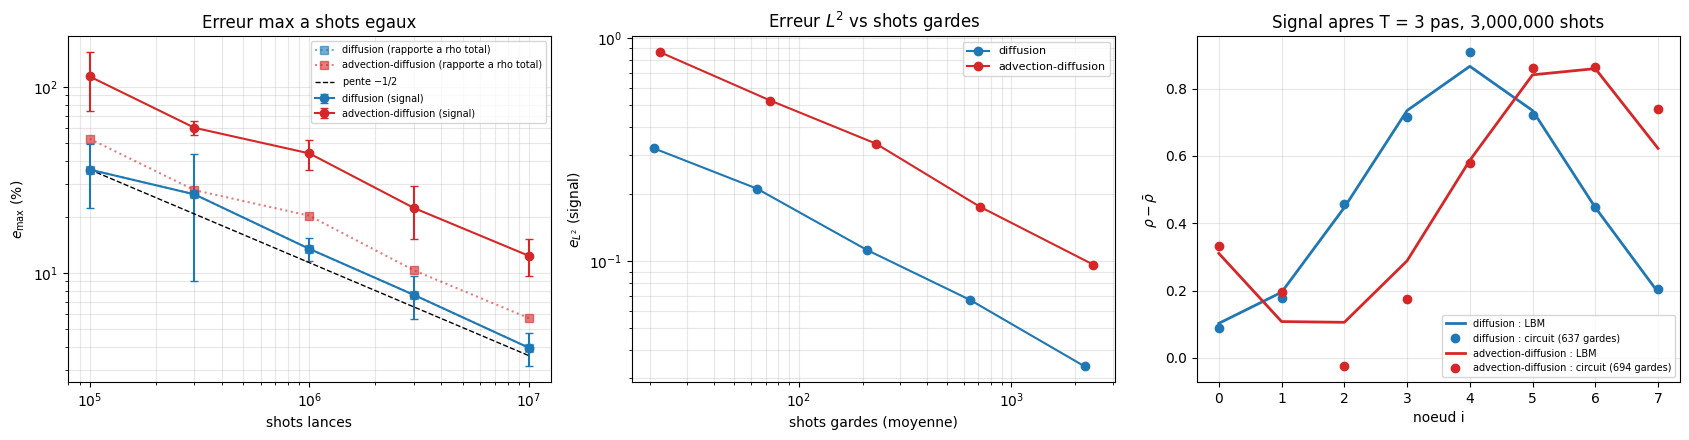

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
cols = {"diffusion": "tab:blue", "advection-diffusion": "tab:red"}
S_ = np.array(liste_shots)

a = ax[0]
for m in modeles:
    r = m["res"]; col = cols[m["nom"]]
    a.errorbar(S_, 100*r["emax"].mean(1), yerr=100*r["emax"].std(1), fmt="o-", color=col, capsize=3, label=f"{m['nom']} (signal)")
    a.plot(S_, 100*r["emax_tot"].mean(1), "s:", color=col, alpha=0.6, label=f"{m['nom']} (rapporte a rho total)")
ref = 100*diff["res"]["emax"].mean(1)[0]
a.loglog(S_, ref*np.sqrt(S_[0]/S_), "k--", lw=1, label=r"pente $-1/2$")
a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("shots lances"); a.set_ylabel(r"$e_{\max}$ (%)")
a.grid(alpha=0.3, which="both"); a.legend(fontsize=7); a.set_title("Erreur max a shots egaux")

a = ax[1]
for m in modeles:
    r = m["res"]; col = cols[m["nom"]]
    a.loglog(r["garde"].mean(1), r["el2"].mean(1), "o-", color=col, label=m["nom"])
a.set_xlabel("shots gardes (moyenne)"); a.set_ylabel(r"$e_{L^2}$ (signal)")
a.grid(alpha=0.3, which="both"); a.legend(fontsize=8); a.set_title(r"Erreur $L^2$ vs shots gardes")

a = ax[2]
n_ref = 3_000_000; i_ref = liste_shots.index(n_ref)
for m in modeles:
    P, garde = executer(m, n_ref, graines[0]); r = reconstruire(m, P, garde)
    col = cols[m["nom"]]
    a.plot(x, m["rho_lbm"] - m["fond"], "-", color=col, lw=2, label=f"{m['nom']} : LBM")
    a.plot(x, r - m["fond"], "o", color=col, label=f"{m['nom']} : circuit ({garde} gardes)")
a.set_xlabel("noeud i"); a.set_ylabel(r"$\rho - \bar\rho$"); a.grid(alpha=0.3); a.legend(fontsize=7)
a.set_title(f"Signal apres T = {T} pas, {n_ref:,} shots")
plt.tight_layout(); plt.show()

### 6.1 Contrôle : d'où vient l'écart de précision ?

Hypothèse : l'écart vient du **fond** $\bar\rho=1$. En advection, le signal ne porte que 32 % de la masse, donc une part des *shots* gardés mesure le fond.
Test : on refait la mesure pour la **diffusion avec le même fond** $\bar\rho=1$ (modèle linéaire : le fond reste constant, la physique est inchangée).

In [10]:
diff_fond = dict(nom="diffusion + fond", E=E_diff, fond=rho_bar, f0=w[:, None]*(rho_bar + g0))
m = diff_fond
m["C_loc"] = diff["C_loc"]
m["F0"] = np.concatenate([m["f0"].reshape(-1), np.zeros(N)]); m["masse"] = m["F0"].sum()
f = m["f0"].copy()
for _ in range(T):
    f = lbm_step(f, m["E"])
m["rho_lbm"] = f.sum(axis=0); m["signal"] = m["rho_lbm"] - m["fond"]
construire(m); m["circ_t"] = transpile(m["circ"], sim)
m["p_exact"], _ = etat_final_exact(m)

shots_ctrl = [3_000_000, 10_000_000]
print(f"{'shots':>12s}{'diffusion':>14s}{'diff. + fond':>15s}{'advection':>12s}   (e_max signal, moyenne sur {len(graines)} graines)")
for s_ in shots_ctrl:
    e = []
    for g in graines:
        P, garde = executer(m, s_, g); r = reconstruire(m, P, garde)
        e.append(np.abs(r - m["rho_lbm"]).max()/m["signal"].max())
    i = liste_shots.index(s_)
    print(f"{s_:>12,}{100*diff['res']['emax'][i].mean():>13.1f}%{100*np.mean(e):>14.1f}%{100*adv['res']['emax'][i].mean():>11.1f}%")
print(f"proba de succes (3 pas) : diffusion {diff['p_exact']:.2e} | diffusion + fond {m['p_exact']:.2e} | advection {adv['p_exact']:.2e}")

       shots     diffusion   diff. + fond   advection   (e_max signal, moyenne sur 3 graines)


   3,000,000          7.6%          16.3%       22.3%


  10,000,000          4.0%           7.3%       12.3%
proba de succes (3 pas) : diffusion 2.20e-04 | diffusion + fond 2.41e-04 | advection 2.41e-04


## 7. Précision du schéma classique

Écart entre le LBM classique et la solution analytique de chaque modèle. Cette erreur est indépendante du quantique : c'est la référence en dessous de laquelle il est inutile de pousser l'erreur statistique.

diffusion              |rho_LBM - rho_analytique|_max = 2.19e-02  (2.5 % du pic du signal)
advection-diffusion    |rho_LBM - rho_analytique|_max = 6.12e-02  (7.1 % du pic du signal)


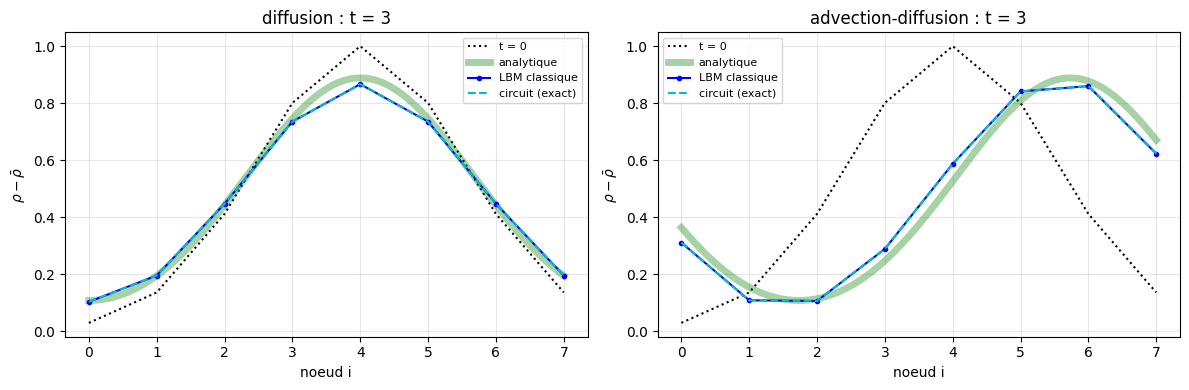

In [11]:
for m in modeles:
    th = m["ana"](T)
    e = np.abs(m["rho_lbm"] - th).max()
    print(f"{m['nom']:22s} |rho_LBM - rho_analytique|_max = {e:.2e}  ({100*e/m['signal'].max():.1f} % du pic du signal)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xf = np.linspace(0, N - 1, 200)
for a, m in zip(ax, modeles):
    a.plot(x, m["f0"].sum(0) - m["fond"], "k:", label="t = 0")
    a.plot(xf, m["ana"](T, xf) - m["fond"], "g-", lw=5, alpha=0.35, label="analytique")
    a.plot(x, m["signal"], "b.-", label="LBM classique")
    a.plot(x, m["rho_q_exact"] - m["fond"], "c--", label="circuit (exact)")
    a.set_title(f"{m['nom']} : t = {T}"); a.set_xlabel("noeud i"); a.set_ylabel(r"$\rho-\bar\rho$")
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Tableau récapitulatif

In [12]:
i3 = liste_shots.index(3_000_000); i10 = liste_shots.index(10_000_000)
lignes = [
    ("width (qubits)",               lambda m: f"{m['cout_total']['qubits']}"),
    ("depth",                        lambda m: f"{m['cout_total']['depth']}"),
    ("2-qubit depth",                lambda m: f"{m['cout_total']['depth_2q']}"),
    ("CNOT",                         lambda m: f"{m['cout_total']['cx']}"),
    ("portes (total)",               lambda m: f"{m['cout_total']['gates']}"),
    ("prep. F0 : CNOT / depth",      lambda m: f"{m['cout_prep']['cx']} / {m['cout_prep']['depth']}"),
    ("collision : CNOT / pas",       lambda m: f"{m['cout_coll']['cx']}"),
    ("streaming : CNOT / pas",       lambda m: f"{m['cout_strm']['cx']}"),
    ("t FABLE (ms)",                 lambda m: f"{1e3*m['t_fable']:.2f}"),
    ("t transpilation (ms)",         lambda m: f"{1e3*m['t_transpile']:.1f}"),
    (f"t simulation {n_temps:,} shots (s)", lambda m: f"{m['t_sim']:.2f}"),
    ("succes par pas",               lambda m: " / ".join(f"{p:.4f}" for p in m["p_pas"])),
    (f"succes cumule ({T} pas)",     lambda m: f"{np.prod(m['p_pas']):.2e}"),
    ("e_max signal, 3M shots",       lambda m: f"{100*m['res']['emax'][i3].mean():.1f} %"),
    ("e_max signal, 10M shots",      lambda m: f"{100*m['res']['emax'][i10].mean():.1f} %"),
    ("e_L2 signal, 10M shots",       lambda m: f"{m['res']['el2'][i10].mean():.3f}"),
    ("LBM vs analytique (% pic)",    lambda m: f"{100*np.abs(m['rho_lbm'] - m['ana'](T)).max()/m['signal'].max():.1f} %"),
]
print(f"{'':34s}{'diffusion':>26s}{'advection-diffusion':>28s}")
for nom, fn in lignes:
    print(f"{nom:34s}{fn(diff):>26s}{fn(adv):>28s}")

                                                   diffusion         advection-diffusion
width (qubits)                                            14                          14
depth                                                   1641                        1641
2-qubit depth                                            894                         894
CNOT                                                     948                         948
portes (total)                                          2003                        2003
prep. F0 : CNOT / depth                              26 / 53                     26 / 53
collision : CNOT / pas                                    22                          22
streaming : CNOT / pas                                   314                         314
t FABLE (ms)                                            0.25                        0.28
t transpilation (ms)                                    51.4                        50.4
t simulation 1,000,00

## 9. Conclusions

**1. Coût du circuit : identique.**
- Largeur 14 qubits, profondeur 1641, profondeur 2-qubits 894, 948 CNOT, 2003 portes pour les deux méthodes.
- Seuls les angles $R_y$ de FABLE et les amplitudes préparées changent, pas la structure du circuit.
- Le streaming domine : 314 CNOT par pas, contre 22 pour la collision.

**2. Chargement : identique.**
- Préparation de $|F^0\rangle$ : 26 CNOT et profondeur 53 dans les deux cas.
- Temps classiques équivalents : FABLE $<0{,}3$ ms, transpilation $\approx 50$ ms, simulation $\approx 0{,}8$ s par million de *shots* (sur cette machine).

**3. Probabilité de succès : légèrement meilleure en advection.**
- Elle vaut exactement $1/16$ au 1ᵉʳ pas dans les deux cas (état initial à l'équilibre).
- Sur 3 pas : $2{,}41\times10^{-4}$ en advection contre $2{,}20\times10^{-4}$ en diffusion, soit 4 150 contre 4 551 *shots* lancés par *shot* gardé.

**4. Précision à *shots* égaux : nettement moins bonne en advection.**
- À 10 M *shots* : $e_{\max}=12{,}3\,\%$ contre $4{,}0\,\%$, et $e_{L^2}=0{,}097$ contre $0{,}034$.
- Comme l'erreur décroît en $1/\sqrt{n}$, atteindre la même précision demande environ $(0{,}097/0{,}034)^2\approx 8$ fois plus de *shots*.

**5. Origine de l'écart (contrôle 6.1).**
- La diffusion avec le même fond $\bar\rho=1$ passe de 4,0 % à 7,3 % (10 M *shots*) : **le fond explique une grande part de l'écart**.
- Il n'explique pas tout (7,3 % contre 12,3 %), il est du même ordre que la dispersion entre les 3 graines ((σ ≈ 2,8 points)) : on ne peut pas encore dire si il est significatif. 

**6. Schéma classique.**
- LBM vs analytique : 2,5 % du pic en diffusion, 7,1 % en advection. La solution d'advection-diffusion est un développement en $k$, grossier sur 8 nœuds.
- À 10 M *shots*, l'erreur statistique domine encore dans les deux cas.

**Bilan.** Passer à l'advection-diffusion ne coûte **rien** en circuit (portes, profondeur, chargement). Le surcoût est **à la mesure** : le signal ne porte que 32 % de la masse.

**Piste.**
- Réduire le fond au minimum compatible avec $f\ge0$. À $t=0$, $f_-=\tfrac16\big(\bar\rho-(\sqrt3-1)\,\delta\rho\big)$, d'où $\bar\rho\ge(\sqrt3-1)A_0\approx0{,}73\,A_0$.
- Cette borne est à vérifier sur toute la simulation, puis à remesurer.
